In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

# Set project directories
project_dir = Path.cwd().resolve().parent
data_dir = project_dir / "data"
results_dir = project_dir / "results"
figures_dir = project_dir / "figures"

results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# Load normalized data
expression = pd.read_csv(
    data_dir / "expression_normalized.csv",
    index_col=0
)

metadata = pd.read_csv(
    data_dir / "metadata_normalized.csv",
    dtype={"Sample_ID": str}
)

expression.columns = expression.columns.astype(str)
metadata = metadata.set_index("Sample_ID")
metadata = metadata.loc[expression.columns]

# Log2 transform
log_expression = np.log2(expression + 1)

print("Expression matrix:", log_expression.shape)
print("\nSample groups:")
print(metadata["Group"].value_counts())

Expression matrix: (730, 32)

Sample groups:
Group
Early-onset PE    13
Healthy           13
Late-onset PE      6
Name: count, dtype: int64


Creating a reusable differential expression function

In [3]:
def run_de_analysis(group1, group2):
    """
    Exploratory differential expression using Welch's t-test.
    Positive log2FC = higher expression in group1.
    """

    samples1 = metadata.index[
        metadata["Group"] == group1
    ]

    samples2 = metadata.index[
        metadata["Group"] == group2
    ]

    expr1 = log_expression[samples1]
    expr2 = log_expression[samples2]

    # Welch's t-test
    stat, pvalues = ttest_ind(
        expr1,
        expr2,
        axis=1,
        equal_var=False
    )

    # Difference in mean log2 expression
    log2fc = expr1.mean(axis=1) - expr2.mean(axis=1)

    results = pd.DataFrame({
        "Gene": log_expression.index,
        "log2FC": log2fc.values,
        "pvalue": pvalues
    })

    # Handle any non-finite p-values
    valid = np.isfinite(results["pvalue"])
    results["padj"] = np.nan

    if valid.any():
        results.loc[valid, "padj"] = multipletests(
            results.loc[valid, "pvalue"],
            method="fdr_bh"
        )[1]

    results = results.sort_values("padj")

    return results

In [4]:
early_vs_healthy = run_de_analysis(
    "Early-onset PE",
    "Healthy"
)

print("Early-onset PE vs. Healthy")

print("Genes tested:", len(early_vs_healthy))

print(
    "Significant genes (FDR < 0.05):",
    (early_vs_healthy["padj"] < 0.05).sum()
)

display(early_vs_healthy.head(10))

Early-onset PE vs. Healthy
Genes tested: 730
Significant genes (FDR < 0.05): 58


,Gene,log2FC,pvalue,padj
212,CX3CR1,-2.241847,4.428808e-08,0.000032
248,ENG,1.272924,8.105312e-07,0.000296
349,IL12RB2,-0.970778,1.915551e-06,0.000466
315,IDO1,-1.008074,1.782379e-05,0.003253
636,ST6GAL1,-0.837400,2.278790e-05,0.003327
711,TRAF3,-0.671471,3.227931e-05,0.003927
619,SLAMF1,-1.818916,4.660191e-05,0.004543
724,VEGFC,0.921580,5.600550e-05,0.004543
195,CSF1,-0.800052,5.569680e-05,0.004543
256,F13A1,-0.768702,7.599926e-05,0.005548


In [5]:
late_vs_healthy = run_de_analysis(
    "Late-onset PE",
    "Healthy"
)

print("Late-onset PE vs. Healthy")

print("Genes tested:", len(late_vs_healthy))

print(
    "Significant genes (FDR < 0.05):",
    (late_vs_healthy["padj"] < 0.05).sum()
)

display(late_vs_healthy.head(10))

Late-onset PE vs. Healthy
Genes tested: 730
Significant genes (FDR < 0.05): 1


,Gene,log2FC,pvalue,padj
241,DUSP6,0.657383,0.000019,0.013847
611,SEMG1,0.795790,0.002347,0.134293
201,CT45A1,0.430099,0.002784,0.134293
334,IFNL1,0.562161,0.002505,0.134293
141,CD55,-0.505043,0.001425,0.134293
657,TFEB,0.358465,0.002393,0.134293
472,LRRN3,-0.699497,0.002234,0.134293
65,CASP8,0.211677,0.001628,0.134293
344,IL11,0.538623,0.001221,0.134293
477,LTK,0.535944,0.003348,0.134293


In [6]:
early_vs_healthy.to_csv(
    results_dir / "early_vs_healthy_exploratory.csv",
    index=False
)

late_vs_healthy.to_csv(
    results_dir / "late_vs_healthy_exploratory.csv",
    index=False
)

print("Both differential expression results saved!")

Both differential expression results saved!


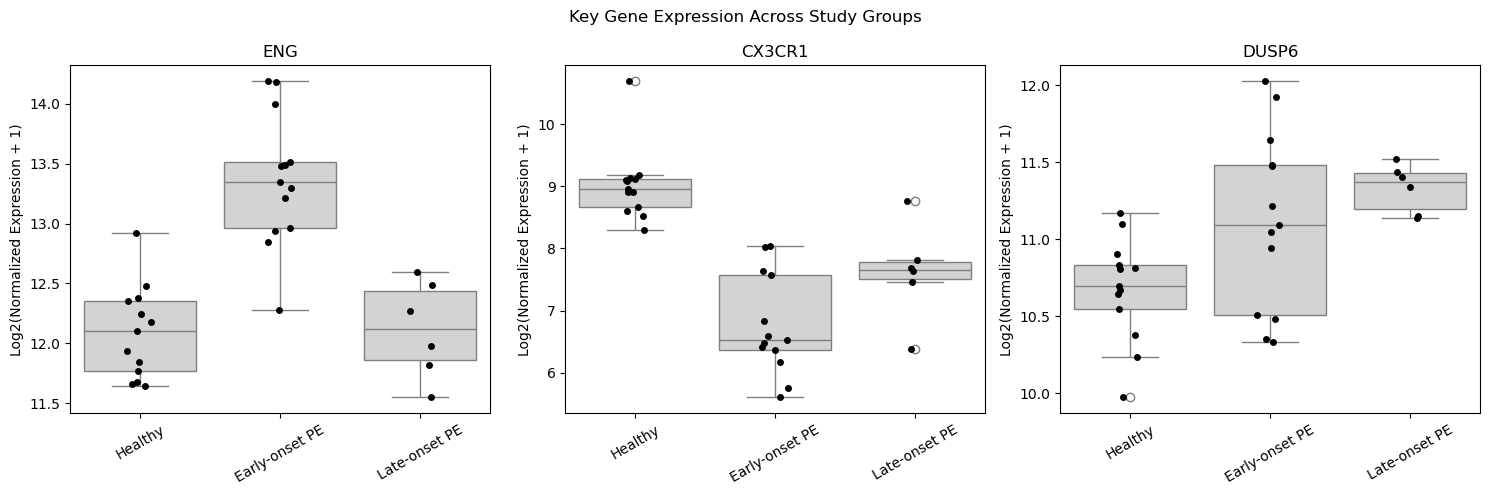

In [7]:
genes_to_plot = ["ENG", "CX3CR1", "DUSP6"]

plot_data = (
    log_expression.loc[genes_to_plot]
    .T
    .join(metadata[["Group"]])
    .reset_index(names="Sample_ID")
    .melt(
        id_vars=["Sample_ID", "Group"],
        var_name="Gene",
        value_name="Log2_Expression"
    )
)

group_order = [
    "Healthy",
    "Early-onset PE",
    "Late-onset PE"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, gene in zip(axes, genes_to_plot):

    subset = plot_data[plot_data["Gene"] == gene]

    sns.boxplot(
        data=subset,
        x="Group",
        y="Log2_Expression",
        order=group_order,
        ax=ax,
        color="lightgray"
    )

    sns.stripplot(
        data=subset,
        x="Group",
        y="Log2_Expression",
        order=group_order,
        ax=ax,
        color="black",
        size=5,
        jitter=True
    )

    ax.set_title(gene)
    ax.set_xlabel("")
    ax.set_ylabel("Log2(Normalized Expression + 1)")
    ax.tick_params(axis="x", rotation=30)

plt.suptitle("Key Gene Expression Across Study Groups")
plt.tight_layout()

plt.savefig(
    figures_dir / "key_genes_group_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Examining the available clinical metadate

In [9]:
import GEOparse
import pandas as pd

# Load the existing GEO SOFT file
gse = GEOparse.get_GEO(
    filepath=str(
        data_dir / "GSE190639_family.soft.gz"
    ),
    silent=True
)

# Examine available fields for the first sample
first_gsm = next(iter(gse.gsms.values()))

for key, value in first_gsm.metadata.items():
    print(f"{key}: {value}")

title: ['placenta_eoPE_136']
geo_accession: ['GSM5726936']
status: ['Public on Dec 13 2021']
submission_date: ['Dec 10 2021']
last_update_date: ['Dec 13 2021']
type: ['RNA']
channel_count: ['1']
source_name_ch1: ['placenta']
organism_ch1: ['Homo sapiens']
taxid_ch1: ['9606']
characteristics_ch1: ['group: eoPE', 'mode of delivery: vaginally', 'gestational age (weeks): 31.86', 'bmi: 31.9', 'birth weight (grams): 1600', 'fetal sex: female']
molecule_ch1: ['total RNA']
extract_protocol_ch1: ['RNA was extracted from snap-frozen placenta samples using the Qiagen RNA easy mini kit.']
label_ch1: ['n.a.']
label_protocol_ch1: ['n.a.']
hyb_protocol: ['A total of 200 ng RNA was hybridized to the PanCancer Immune Profiling Panel for 17 hours at 67°C, following the manufacturing procedure (NanoString, Seattle, USA).']
scan_protocol: ['The nCounter FLEX platform was used and genes were counted by scanning 490 Fields-of-view (FOV).']
data_processing: ['Data analysis was performed using the advanced an

In [10]:
import pandas as pd

clinical_records = []

for gsm_id, gsm in gse.gsms.items():

    title = gsm.metadata["title"][0]
    sample_id = title.split("_")[-1]

    # Extract characteristics
    characteristics = {}

    for item in gsm.metadata.get("characteristics_ch1", []):
        if ": " in item:
            key, value = item.split(": ", 1)
            characteristics[key.strip()] = value.strip()

    clinical_records.append({
        "GSM_ID": gsm_id,
        "Sample_ID": sample_id,
        "Group": characteristics.get("group"),
        "Gestational_Age": characteristics.get(
            "gestational age (weeks)"
        ),
        "BMI": characteristics.get("bmi"),
        "Birth_Weight": characteristics.get(
            "birth weight (grams)"
        ),
        "Fetal_Sex": characteristics.get("fetal sex"),
        "Delivery_Mode": characteristics.get(
            "mode of delivery"
        )
    })

clinical_df = pd.DataFrame(clinical_records)

# Convert numerical clinical variables
for col in ["Gestational_Age", "BMI", "Birth_Weight"]:
    clinical_df[col] = pd.to_numeric(
        clinical_df[col],
        errors="coerce"
    )

print("Clinical metadata shape:", clinical_df.shape)

print("\nStudy groups:")
print(clinical_df["Group"].value_counts(dropna=False))

display(clinical_df.head(10))

Clinical metadata shape: (32, 8)

Study groups:
Group
eoPE       13
healthy    13
loPE        6
Name: count, dtype: int64


,GSM_ID,Sample_ID,Group,Gestational_Age,BMI,Birth_Weight,Fetal_Sex,Delivery_Mode
0,GSM5726936,136,eoPE,31.86,31.9,1600,female,vaginally
1,GSM5726937,137,eoPE,29.86,24.3,884,female,section
2,GSM5726938,161,eoPE,28.29,23.4,910,female,section
3,GSM5726939,170,eoPE,29.14,32.5,1170,male,section
4,GSM5726940,172,eoPE,30.57,35.1,1300,female,section
5,GSM5726941,175,eoPE,28.57,20.9,1080,male,section
6,GSM5726942,176,eoPE,32.00,NaN,1150,male,section
7,GSM5726943,197,eoPE,31.57,23.1,1460,male,section
8,GSM5726944,219,eoPE,34.86,21.4,1780,male,section
9,GSM5726945,220,eoPE,28.71,26.4,940,female,section


In [11]:
clinical_summary = (
    clinical_df
    .groupby("Group")
    .agg(
        n=("Sample_ID", "count"),
        Gestational_Age_Mean=("Gestational_Age", "mean"),
        Gestational_Age_Min=("Gestational_Age", "min"),
        Gestational_Age_Max=("Gestational_Age", "max"),
        BMI_Mean=("BMI", "mean"),
        BMI_SD=("BMI", "std")
    )
)

display(clinical_summary.round(2))

print("\nMissing clinical values:")
print(clinical_df.isna().sum())

,n,Gestational_Age_Mean,Gestational_Age_Min,Gestational_Age_Max,BMI_Mean,BMI_SD
Group,,,,,,
eoPE,13,30.47,28.29,34.86,26.37,5.02
healthy,13,38.65,35.43,39.86,26.60,5.95
loPE,6,35.98,34.29,37.29,27.47,6.55



Missing clinical values:
GSM_ID             0
Sample_ID          0
Group              0
Gestational_Age    0
BMI                1
Birth_Weight       0
Fetal_Sex          0
Delivery_Mode      0
dtype: int64


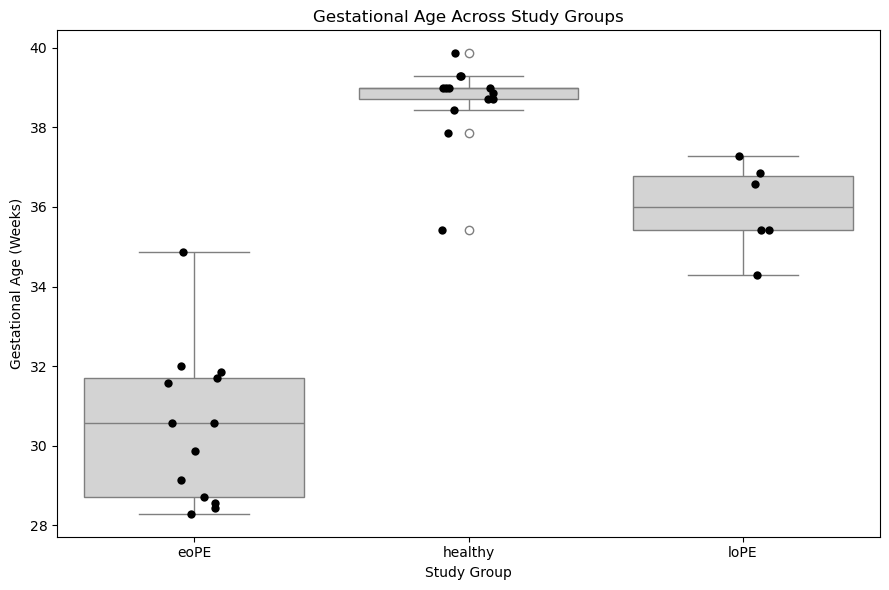

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=clinical_df,
    x="Group",
    y="Gestational_Age",
    color="lightgray"
)

sns.stripplot(
    data=clinical_df,
    x="Group",
    y="Gestational_Age",
    color="black",
    jitter=True,
    size=6
)

plt.title("Gestational Age Across Study Groups")
plt.xlabel("Study Group")
plt.ylabel("Gestational Age (Weeks)")

plt.tight_layout()

plt.savefig(
    figures_dir / "gestational_age_by_group.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
clinical_df.to_csv(
    data_dir / "clinical_metadata.csv",
    index=False
)

print("Clinical metadata saved successfully!")

Clinical metadata saved successfully!


In [15]:
# Load saved PCA results
pca_clinical = pd.read_csv(
    results_dir / "pca_results.csv",
    index_col=0
)

pca_clinical.index = pca_clinical.index.astype(str)

# Prepare clinical metadata
clinical_aligned = clinical_df.set_index("Sample_ID")
clinical_aligned.index = clinical_aligned.index.astype(str)

# Combine PCA and clinical data
pca_clinical = pca_clinical.join(
    clinical_aligned[["Gestational_Age", "BMI"]],
    how="inner",
    validate="one_to_one"
)

print("Matched samples:", len(pca_clinical))

print("\nCorrelations with gestational age:")
print(
    pca_clinical[
        ["PC1", "PC2", "Gestational_Age"]
    ].corr()["Gestational_Age"]
)

Matched samples: 32

Correlations with gestational age:
PC1                0.311184
PC2               -0.242033
Gestational_Age    1.000000
Name: Gestational_Age, dtype: float64


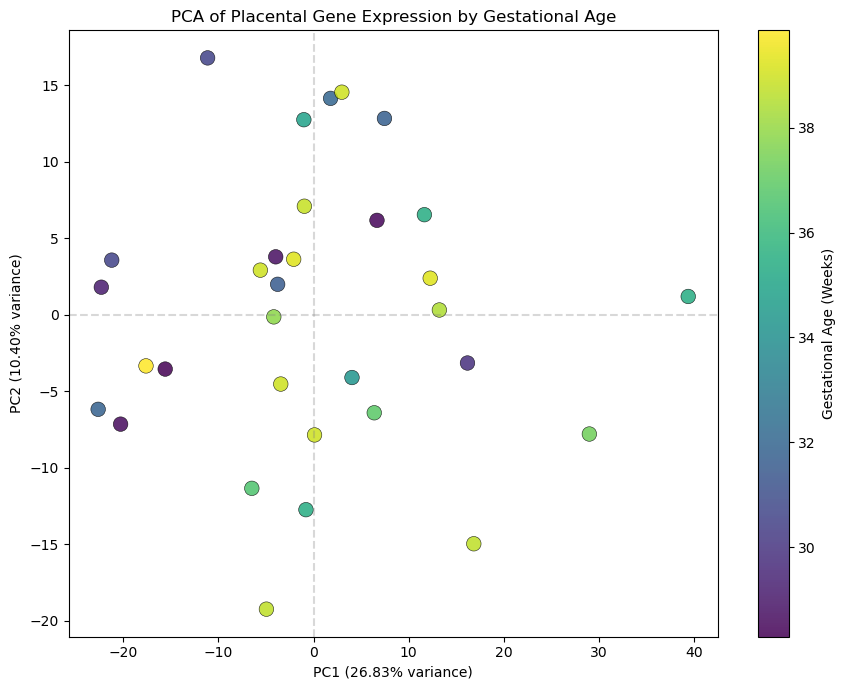

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 7))

scatter = plt.scatter(
    pca_clinical["PC1"],
    pca_clinical["PC2"],
    c=pca_clinical["Gestational_Age"],
    cmap="viridis",
    s=110,
    alpha=0.85,
    edgecolors="black",
    linewidths=0.4
)

plt.colorbar(
    scatter,
    label="Gestational Age (Weeks)"
)

plt.xlabel("PC1 (26.83% variance)")
plt.ylabel("PC2 (10.40% variance)")
plt.title("PCA of Placental Gene Expression by Gestational Age")

plt.axhline(0, color="gray", linestyle="--", alpha=0.3)
plt.axvline(0, color="gray", linestyle="--", alpha=0.3)

plt.tight_layout()

plt.savefig(
    figures_dir / "PCA_gestational_age.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
import pandas as pd
from pathlib import Path

# Locate project folder
project_dir = Path.cwd().resolve().parent
results_dir = project_dir / "results"

# Load limma results
early_late = pd.read_csv(
    results_dir / "limma_Early_vs_Late.csv",
    index_col=0
)

early_healthy = pd.read_csv(
    results_dir / "limma_Early_vs_Healthy.csv",
    index_col=0
)

late_healthy = pd.read_csv(
    results_dir / "limma_Late_vs_Healthy.csv",
    index_col=0
)

print("All three limma result files loaded!")

All three limma result files loaded!


In [22]:
comparisons = {
    "Early vs Late": early_late,
    "Early vs Healthy": early_healthy,
    "Late vs Healthy": late_healthy
}

for name, df in comparisons.items():

    significant = df[df["adj.P.Val"] < 0.05]

    print(f"\n{name}")
    print("Genes tested:", len(df))
    print("Significant genes:", len(significant))

    display(df.head(5))


Early vs Late
Genes tested: 730
Significant genes: 6


,logFC,AveExpr,t,P.Value,adj.P.Val,B
ENG,1.246786,12.612691,5.484919,0.000005,0.003579,4.047988
CEACAM1,-0.861637,7.706398,-4.741072,0.000042,0.015496,2.101487
BATF,-0.843373,6.050905,-4.331198,0.000138,0.033538,1.038530
IDO1,-0.981739,10.880878,-4.219757,0.000189,0.034542,0.752453
IL12RB2,-0.770162,7.511955,-4.049974,0.000306,0.043251,0.319926



Early vs Healthy
Genes tested: 730
Significant genes: 69


,logFC,AveExpr,t,P.Value,adj.P.Val,B
CX3CR1,-2.241847,7.842656,-8.289963,1.855183e-09,0.000001,11.579842
ENG,1.272924,12.612691,7.046394,5.575163e-08,0.000020,8.365932
IL12RB2,-0.970778,7.511955,-6.423562,3.258527e-07,0.000079,6.688229
SLAMF1,-1.818916,5.127907,-5.636098,3.160126e-06,0.000577,4.524336
TRAF3,-0.671471,8.717248,-5.525348,4.358888e-06,0.000636,4.217909



Late vs Healthy
Genes tested: 730
Significant genes: 0


,logFC,AveExpr,t,P.Value,adj.P.Val,B
IL23R,0.818574,3.614996,4.210761,0.000194,0.095103,0.634164
CX3CR1,-1.386667,7.842656,-4.075046,0.000285,0.095103,0.312224
VEGFC,0.914703,8.933683,3.962665,0.000391,0.095103,0.047367
MAP2K4,-0.574139,9.043555,-3.484956,0.001455,0.265608,-1.054571
TLR9,0.714493,3.588759,3.232821,0.002849,0.322360,-1.615261


In [23]:
# Get all significant genes from limma
significant_limma = early_late[
    early_late["adj.P.Val"] < 0.05
].copy()

print("Total significant genes:", len(significant_limma))

display(
    significant_limma[
        ["logFC", "P.Value", "adj.P.Val"]
    ]
)

# Save the significant genes
significant_limma.to_csv(
    results_dir / "significant_genes_early_vs_late_limma.csv"
)

Total significant genes: 6


,logFC,P.Value,adj.P.Val
ENG,1.246786,0.000005,0.003579
CEACAM1,-0.861637,0.000042,0.015496
BATF,-0.843373,0.000138,0.033538
IDO1,-0.981739,0.000189,0.034542
IL12RB2,-0.770162,0.000306,0.043251
MME,1.073678,0.000355,0.043251


In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

project_dir = Path.cwd().resolve().parent
results_dir = project_dir / "results"
figures_dir = project_dir / "figures"

figures_dir.mkdir(parents=True, exist_ok=True)

limma_results = pd.read_csv(
    results_dir / "limma_Early_vs_Late.csv",
    index_col=0
)

print("Genes tested:", len(limma_results))
print(
    "Significant genes:",
    (limma_results["adj.P.Val"] < 0.05).sum()
)

display(limma_results.head())

Genes tested: 730
Significant genes: 6


,logFC,AveExpr,t,P.Value,adj.P.Val,B
ENG,1.246786,12.612691,5.484919,0.000005,0.003579,4.047988
CEACAM1,-0.861637,7.706398,-4.741072,0.000042,0.015496,2.101487
BATF,-0.843373,6.050905,-4.331198,0.000138,0.033538,1.038530
IDO1,-0.981739,10.880878,-4.219757,0.000189,0.034542,0.752453
IL12RB2,-0.770162,7.511955,-4.049974,0.000306,0.043251,0.319926


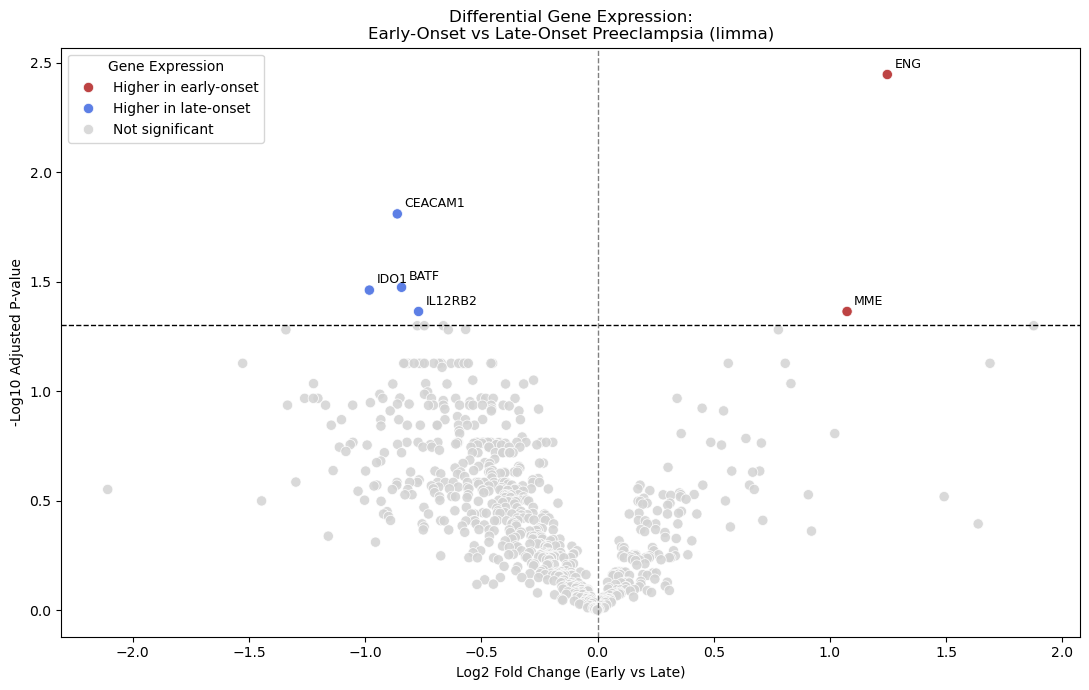

In [25]:
# Prepare the plotting data
volcano = limma_results.copy()

volcano["Gene"] = volcano.index

volcano["neg_log10_FDR"] = -np.log10(
    volcano["adj.P.Val"].clip(lower=1e-300)
)

# Classify significant genes
volcano["Significance"] = "Not significant"

volcano.loc[
    (volcano["adj.P.Val"] < 0.05) &
    (volcano["logFC"] > 0),
    "Significance"
] = "Higher in early-onset"

volcano.loc[
    (volcano["adj.P.Val"] < 0.05) &
    (volcano["logFC"] < 0),
    "Significance"
] = "Higher in late-onset"

# Select significant genes
significant = volcano[
    volcano["adj.P.Val"] < 0.05
]

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=volcano,
    x="logFC",
    y="neg_log10_FDR",
    hue="Significance",
    hue_order=[
        "Higher in early-onset",
        "Higher in late-onset",
        "Not significant"
    ],
    palette={
        "Higher in early-onset": "firebrick",
        "Higher in late-onset": "royalblue",
        "Not significant": "lightgray"
    },
    s=55,
    alpha=0.85
)

plt.axhline(
    -np.log10(0.05),
    color="black",
    linestyle="--",
    linewidth=1
)

plt.axvline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1
)

# Label all six significant genes
for _, row in significant.iterrows():
    plt.annotate(
        row["Gene"],
        (row["logFC"], row["neg_log10_FDR"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

plt.title(
    "Differential Gene Expression:\n"
    "Early-Onset vs Late-Onset Preeclampsia (limma)"
)

plt.xlabel("Log2 Fold Change (Early vs Late)")
plt.ylabel("-Log10 Adjusted P-value")

plt.legend(title="Gene Expression")
plt.tight_layout()

plt.savefig(
    figures_dir / "final_limma_volcano_early_vs_late.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [26]:
expression = pd.read_csv(
    project_dir / "data" / "expression_normalized.csv",
    index_col=0
)

metadata = pd.read_csv(
    project_dir / "data" / "metadata_normalized.csv",
    dtype={"Sample_ID": str}
)

expression.columns = expression.columns.astype(str)

metadata = metadata.set_index("Sample_ID")
metadata = metadata.loc[expression.columns]

log_expression = np.log2(expression + 1)

# Select six significant genes
significant_genes = limma_results.index[
    limma_results["adj.P.Val"] < 0.05
].tolist()

# Arrange samples by subtype
early_samples = metadata.index[
    metadata["Group"] == "Early-onset PE"
].tolist()

late_samples = metadata.index[
    metadata["Group"] == "Late-onset PE"
].tolist()

selected_samples = early_samples + late_samples

# Prepare heatmap
heatmap_data = log_expression.loc[
    significant_genes, selected_samples
]

# Calculate gene-wise Z-scores
heatmap_z = heatmap_data.sub(
    heatmap_data.mean(axis=1), axis=0
).div(
    heatmap_data.std(axis=1), axis=0
)

print("Heatmap dimensions:", heatmap_z.shape)

Heatmap dimensions: (6, 19)


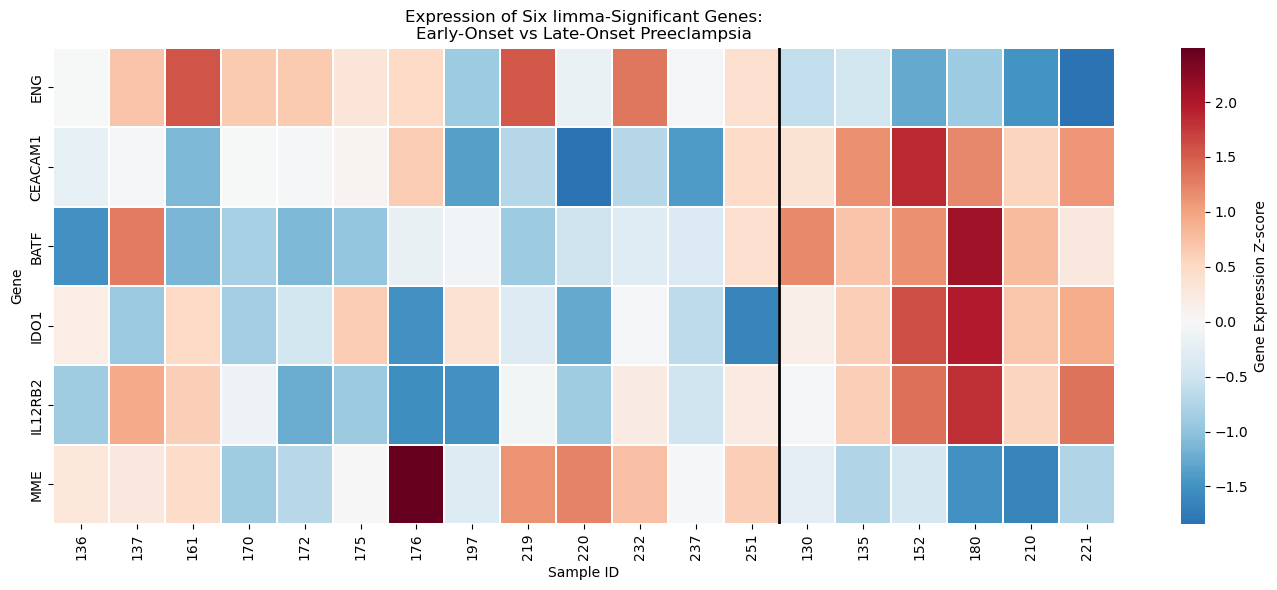

In [27]:
plt.figure(figsize=(14, 6))

sns.heatmap(
    heatmap_z,
    cmap="RdBu_r",
    center=0,
    linewidths=0.3,
    cbar_kws={"label": "Gene Expression Z-score"}
)

# Separate early and late groups
plt.axvline(
    x=len(early_samples),
    color="black",
    linewidth=2
)

plt.title(
    "Expression of Six limma-Significant Genes:\n"
    "Early-Onset vs Late-Onset Preeclampsia"
)

plt.xlabel("Sample ID")
plt.ylabel("Gene")
plt.xticks(rotation=90)

plt.tight_layout()

plt.savefig(
    figures_dir / "final_limma_heatmap_early_vs_late.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [28]:
import pandas as pd

# Load gestational-age adjusted results
adjusted_results = pd.read_csv(
    results_dir / "limma_gestational_age_sensitivity.csv",
    index_col=0
)

print("Genes tested:", len(adjusted_results))

print(
    "Significant genes (FDR < 0.05):",
    (adjusted_results["adj.P.Val"] < 0.05).sum()
)

display(adjusted_results.head(10))

Genes tested: 730
Significant genes (FDR < 0.05): 0


,logFC,AveExpr,t,P.Value,adj.P.Val,B
IL1RAP,1.265508,12.235118,3.503406,0.002386,0.605028,-4.410324
IL27,-1.437648,4.669654,-3.366996,0.003249,0.605028,-4.420569
TLR9,-1.155325,3.767834,-3.313300,0.003667,0.605028,-4.424657
TFEB,-0.788932,8.322808,-3.186580,0.004873,0.605028,-4.434420
NRP1,-0.650256,11.769561,-3.011719,0.007192,0.605028,-4.448125
CD34,-1.048993,9.077867,-3.003815,0.007319,0.605028,-4.448750
ITGB4,0.852255,11.687150,2.985639,0.007619,0.605028,-4.450189
IL5RA,1.102657,5.372739,2.974258,0.007813,0.605028,-4.451091
GATA3,1.096839,7.844832,2.948142,0.008276,0.605028,-4.453165
CCND3,-0.841326,8.995252,-2.947500,0.008288,0.605028,-4.453216


In [29]:
genes = ["ENG", "MME", "CEACAM1", "BATF", "IDO1", "IL12RB2"]

display(
    adjusted_results.loc[
        genes,
        ["logFC", "P.Value", "adj.P.Val"]
    ]
)

,logFC,P.Value,adj.P.Val
ENG,1.108578,0.030419,0.92114
MME,1.451305,0.024717,0.92114
CEACAM1,-0.589980,0.139334,0.92114
BATF,-0.699415,0.082425,0.92114
IDO1,-1.035253,0.037572,0.92114
IL12RB2,-0.902396,0.039034,0.92114
